# 05 · Model Evaluation and Comparison

**Goal:** compare all models on the same 4 folds with MAE, RMSE and R², and look at where the errors come from.

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/04.ModelEvaluation"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
from backtest import compute_metrics

predictions = pd.read_csv("data/GeneratedOutput/03.ModelTraining/predictions.csv",
                          index_col="forecast_made_at", parse_dates=["forecast_made_at", "forecast_for"])
scored = predictions[predictions["target_observed"] == 1]
MODELS = ["Persistence", "Seasonal naive", "XGBoost"]
COLORS = {"Persistence": "tab:gray", "Seasonal naive": "tab:olive", "XGBoost": "tab:blue"}
print("Scored hours:", len(scored))

Scored hours: 17333


## 1. Scores per fold and on average

In [3]:
rows = []
for fold, part in scored.groupby("fold"):
    for model in MODELS:
        rows.append({"fold": fold, "model": model, **compute_metrics(part["actual"], part[model])})
per_fold = pd.DataFrame(rows)
per_fold.to_csv(f"{OUT}/metrics_per_fold.csv", index=False)

comparison = per_fold.groupby("model")[["MAE", "RMSE", "R2"]].mean().loc[MODELS].round(3)
comparison["MAE vs persistence"] = (1 - comparison["MAE"] / comparison.loc["Persistence", "MAE"]).map("{:.1%}".format)
comparison.to_csv(f"{OUT}/model_comparison.csv")
comparison

,MAE,RMSE,R2,MAE vs persistence
model,,,,
Persistence,40.732,65.312,0.518,0.0%
Seasonal naive,71.840,104.185,-0.223,-76.4%
XGBoost,35.758,55.798,0.652,12.2%


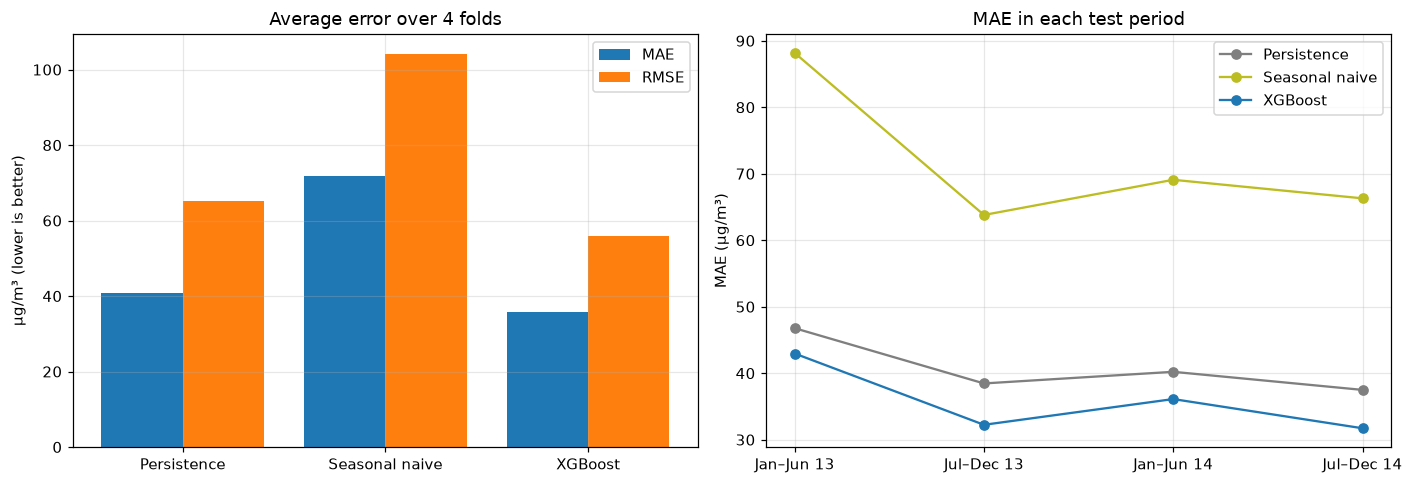

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

x = np.arange(len(MODELS))
axes[0].bar(x - 0.2, comparison["MAE"], width=0.4, label="MAE", color="tab:blue")
axes[0].bar(x + 0.2, comparison["RMSE"], width=0.4, label="RMSE", color="tab:orange")
axes[0].set_xticks(x, MODELS)
axes[0].set_ylabel("µg/m³ (lower is better)")
axes[0].set_title("Average error over 4 folds")
axes[0].legend()

for model in MODELS:
    part = per_fold[per_fold["model"] == model]
    axes[1].plot(part["fold"], part["MAE"], marker="o", label=model, color=COLORS[model])
axes[1].set_xticks([1, 2, 3, 4], ["Jan–Jun 13", "Jul–Dec 13", "Jan–Jun 14", "Jul–Dec 14"])
axes[1].set_ylabel("MAE (µg/m³)")
axes[1].set_title("MAE in each test period")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG}/09_model_comparison.png")
plt.show()

## 2. Forecast vs actual (last 7 days of the last fold)

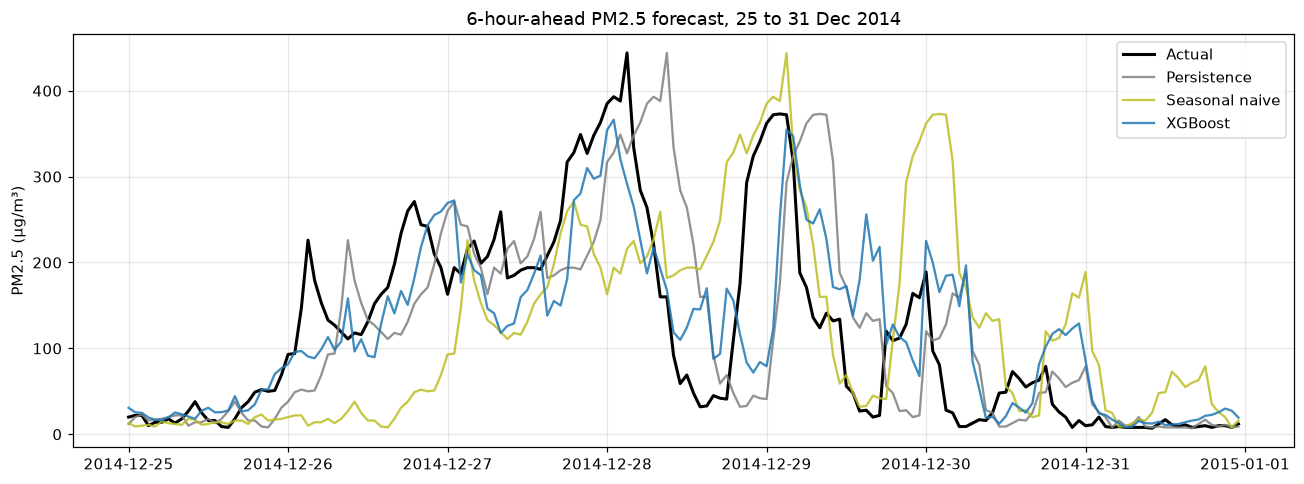

In [5]:
last_week = predictions.tail(7 * 24)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(last_week["forecast_for"], last_week["actual"], color="black", linewidth=2, label="Actual")
for model in MODELS:
    ax.plot(last_week["forecast_for"], last_week[model], label=model, color=COLORS[model], alpha=0.85)
ax.set_title("6-hour-ahead PM2.5 forecast, 25 to 31 Dec 2014")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/10_forecast_vs_actual.png")
plt.show()

## 3. Predicted vs actual

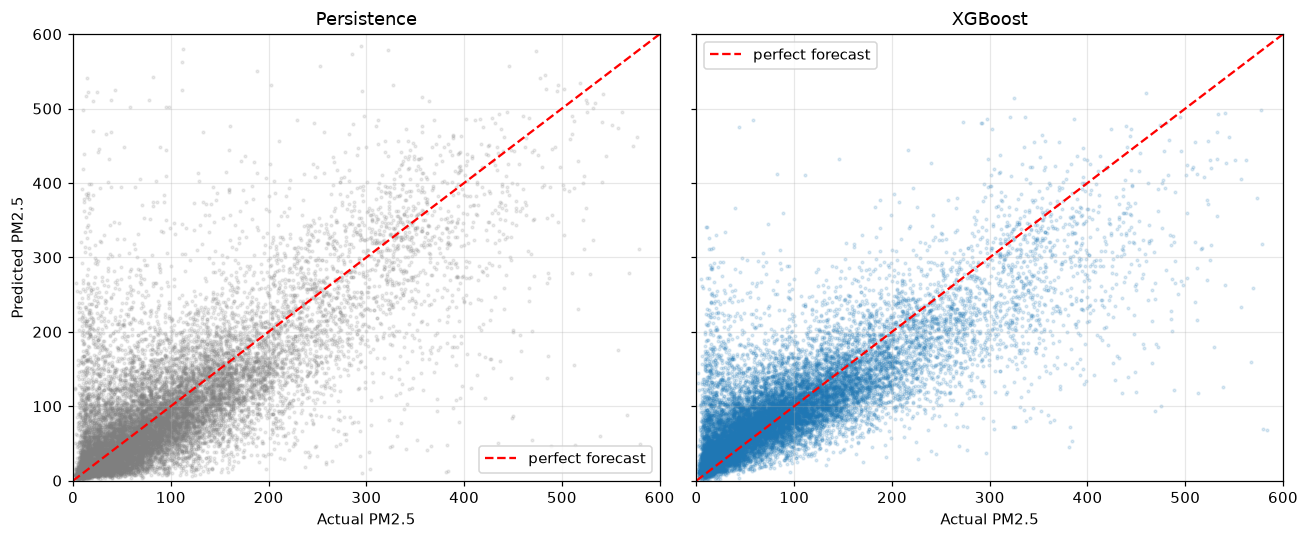

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
limit = 600
for ax, model in zip(axes, ["Persistence", "XGBoost"]):
    ax.scatter(scored["actual"], scored[model], s=3, alpha=0.15, color=COLORS[model])
    ax.plot([0, limit], [0, limit], color="red", linestyle="--", label="perfect forecast")
    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_title(f"{model}")
    ax.set_xlabel("Actual PM2.5")
    ax.legend()
axes[0].set_ylabel("Predicted PM2.5")
plt.tight_layout()
plt.savefig(f"{FIG}/11_predicted_vs_actual.png")
plt.show()

## 4. Where does XGBoost make mistakes?

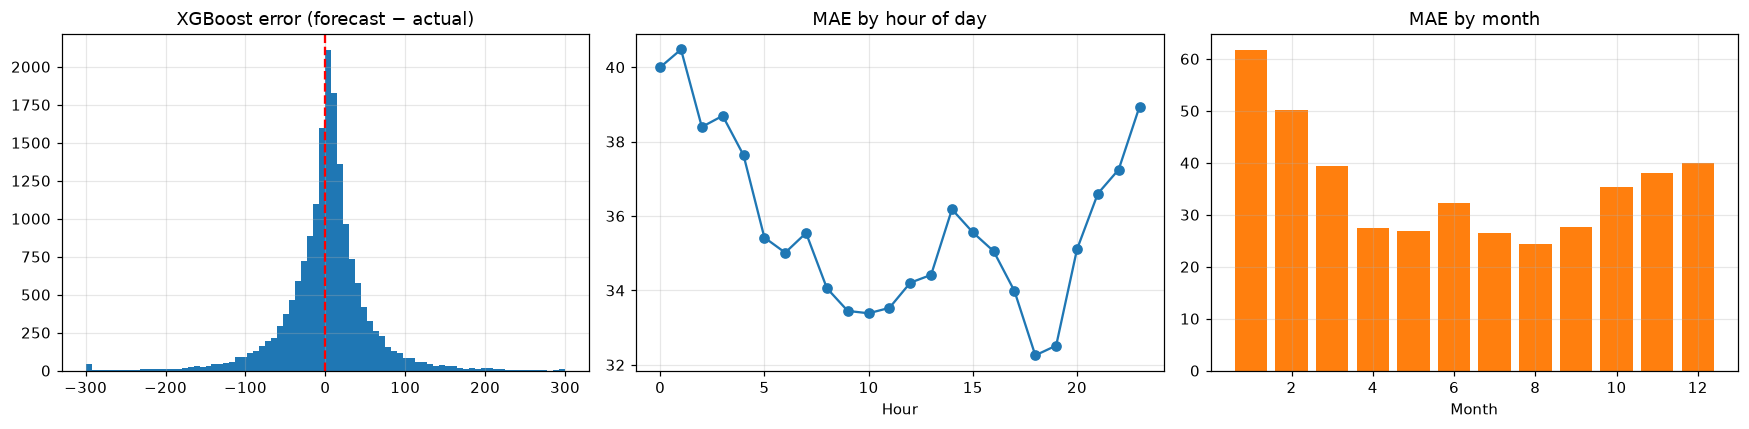

Median error: 4.3 µg/m³
Worst months (highest MAE): {1: 61.7, 2: 50.2, 12: 40.0}


In [7]:
errors = scored.copy()
errors["error"] = errors["XGBoost"] - errors["actual"]
errors["abs_error"] = errors["error"].abs()
by_hour = errors.groupby(errors["forecast_for"].dt.hour)["abs_error"].mean()
by_month = errors.groupby(errors["forecast_for"].dt.month)["abs_error"].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(errors["error"].clip(-300, 300), bins=80, color="tab:blue")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("XGBoost error (forecast − actual)")
axes[1].plot(by_hour.index, by_hour.values, marker="o")
axes[1].set_title("MAE by hour of day")
axes[1].set_xlabel("Hour")
axes[2].bar(by_month.index, by_month.values, color="tab:orange")
axes[2].set_title("MAE by month")
axes[2].set_xlabel("Month")
plt.tight_layout()
plt.savefig(f"{FIG}/12_error_analysis.png")
plt.show()

print("Median error:", round(errors["error"].median(), 1), "µg/m³")
print("Worst months (highest MAE):", by_month.sort_values(ascending=False).head(3).round(1).to_dict())

## Conclusion

- **XGBoost wins in every fold.** Its average MAE is about 35.8 µg/m³ against 40.7 for persistence (about 12% lower), and R² rises from 0.52 to 0.65.
- **Seasonal naive is the weakest** (R² below 0). Yesterday's value is a poor guide 6 hours ahead, because pollution episodes come and go within days.
- Errors are largest in the **winter heating months** and during sudden spikes or drops, when PM2.5 changes faster than 6 hours of history can predict.
- **Next step:** a sequence model (LSTM) can test whether longer temporal patterns reduce these errors.